In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.metrics import root_mean_squared_error, r2_score
from sklearn.pipeline import Pipeline

In [2]:
FILE_PATH = 'Housing.csv'
data = pd.read_csv(FILE_PATH)

In [3]:
data.head()

,rownames,price,lotsize,bedrooms,bathrms,stories,driveway,recroom,fullbase,gashw,airco,garagepl,prefarea
0,1,42000,5850.0,3,1,2,yes,no,yes,no,no,1.0,no
1,2,38500,4000.0,2,1,1,yes,no,no,no,no,0.0,no
2,3,49500,3060.0,3,1,1,yes,no,no,no,no,0.0,no
3,4,60500,6650.0,3,1,2,yes,yes,no,no,no,0.0,no
4,5,61000,6360.0,2,1,1,yes,no,no,no,no,0.0,no


In [4]:
data.tail()

,rownames,price,lotsize,bedrooms,bathrms,stories,driveway,recroom,fullbase,gashw,airco,garagepl,prefarea
541,542,91500,4800.0,3,2,4,yes,yes,no,no,yes,0.0,no
542,543,94000,6000.0,3,2,4,yes,no,no,no,yes,0.0,no
543,544,103000,6000.0,3,2,4,yes,yes,no,no,yes,1.0,no
544,545,105000,6000.0,3,2,2,yes,yes,no,no,yes,1.0,no
545,546,105000,6000.0,3,1,2,yes,no,no,no,yes,1.0,no


In [5]:
data.sample(3)

,rownames,price,lotsize,bedrooms,bathrms,stories,driveway,recroom,fullbase,gashw,airco,garagepl,prefarea
204,205,56000,3290.0,2,1,1,yes,no,no,yes,no,1.0,no
73,74,34000,2475.0,3,1,2,yes,no,no,no,no,0.0,no
511,512,47500,4775.0,4,1,2,yes,no,no,no,no,0.0,no


In [6]:
data.shape

(546, 13)

In [7]:
data.dtypes

rownames      int64
price         int64
lotsize     float64
bedrooms      int64
bathrms       int64
stories       int64
driveway        str
recroom         str
fullbase        str
gashw           str
airco           str
garagepl    float64
prefarea        str
dtype: object

In [8]:
data.isna().sum()

rownames    0
price       0
lotsize     5
bedrooms    0
bathrms     0
stories     0
driveway    2
recroom     4
fullbase    0
gashw       2
airco       7
garagepl    2
prefarea    2
dtype: int64

In [9]:
data.describe()

,rownames,price,lotsize,bedrooms,bathrms,stories,garagepl
count,546.000000,546.000000,541.000000,546.000000,546.000000,546.000000,544.000000
mean,273.500000,68121.597070,5160.611830,2.965201,1.285714,1.807692,0.694853
std,157.760895,26702.670926,2175.141222,0.737388,0.502158,0.868203,0.861864
min,1.000000,25000.000000,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,137.250000,49125.000000,3584.000000,2.000000,1.000000,1.000000,0.000000
50%,273.500000,62000.000000,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,409.750000,82000.000000,6360.000000,3.000000,2.000000,2.000000,1.000000
max,546.000000,190000.000000,16200.000000,6.000000,4.000000,4.000000,3.000000


In [10]:
target_col = 'price'
y = data[target_col].values
X = data.drop(columns=[target_col, 'rownames'])

In [11]:
X.head()

,lotsize,bedrooms,bathrms,stories,driveway,recroom,fullbase,gashw,airco,garagepl,prefarea
0,5850.0,3,1,2,yes,no,yes,no,no,1.0,no
1,4000.0,2,1,1,yes,no,no,no,no,0.0,no
2,3060.0,3,1,1,yes,no,no,no,no,0.0,no
3,6650.0,3,1,2,yes,yes,no,no,no,0.0,no
4,6360.0,2,1,1,yes,no,no,no,no,0.0,no


In [31]:
y

array([ 42000,  38500,  49500,  60500,  61000,  66000,  66000,  69000,
        83800,  88500,  90000,  30500,  27000,  36000,  37000,  37900,
        40500,  40750,  45000,  45000,  48500,  65900,  37900,  38000,
        42000,  42300,  43500,  44000,  44500,  44900,  45000,  48000,
        49000,  51500,  61000,  61000,  61700,  67000,  82000,  54500,
        66500,  70000,  82000,  92000,  38000,  44000,  41000,  43000,
        48000,  54800,  55000,  57000,  68000,  95000,  38000,  25000,
        25245,  56000,  35500,  30000,  48000,  48000,  52000,  54000,
        56000,  60000,  60000,  67000,  47000,  70000,  45000,  51000,
        32500,  34000,  35000,  36000,  45000,  47000,  55000,  63900,
        50000,  35000,  50000,  43000,  55500,  57000,  60000,  78000,
        35000,  44000,  47000,  58000, 163000, 128000, 123500,  39000,
        53900,  59900,  35000,  43000,  57000,  79000, 125000, 132000,
        58000,  43000,  48000,  58500,  73000,  63500,  43000,  46500,
      

In [32]:
numeric_features = (X.select_dtypes(include='number').columns.tolist())
categorical_features = (X.select_dtypes(exclude=np.number).columns.tolist())

In [33]:
numeric_features

['lotsize', 'bedrooms', 'bathrms', 'stories', 'garagepl']

In [34]:
categorical_features

['driveway', 'recroom', 'fullbase', 'gashw', 'airco', 'prefarea']

In [35]:
numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median'))
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features),
    ]
)

In [36]:
X_train, X_test, y_train,  y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [37]:
gbr = GradientBoostingRegressor(random_state=42)

pipe = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('gbr', gbr)]
)

param_grid = {
    'gbr__max_depth': [2, 3, 4],
    'gbr__min_samples_split': [2, 5, 10],
    'gbr__min_samples_leaf': [1, 3, 5, 10],
    'gbr__learning_rate': [0.05],
    'gbr__n_estimators': [400]
}

In [38]:
cv = KFold(n_splits=5, random_state=42, shuffle=True)
grid_search = GridSearchCV(pipe, param_grid, cv=cv, scoring='neg_mean_squared_error', n_jobs=-1, verbose=0)
grid_search.fit(X_train, y_train)
best_model = grid_search.best_estimator_
grid_search.best_params_

{'gbr__learning_rate': 0.05,
 'gbr__max_depth': 2,
 'gbr__min_samples_leaf': 5,
 'gbr__min_samples_split': 2,
 'gbr__n_estimators': 400}

In [39]:
def rmse(y_true, y_pred):
    return root_mean_squared_error(y_true, y_pred)

y_pred = best_model.predict(X_test)
print(f'''
Best params: {grid_search.best_params_}
RMSE: {rmse(y_test, y_pred):.3f}
R2: {r2_score(y_test, y_pred):.2f}
''')


Best params: {'gbr__learning_rate': 0.05, 'gbr__max_depth': 2, 'gbr__min_samples_leaf': 5, 'gbr__min_samples_split': 2, 'gbr__n_estimators': 400}
RMSE: 15777.417
R2: 0.63



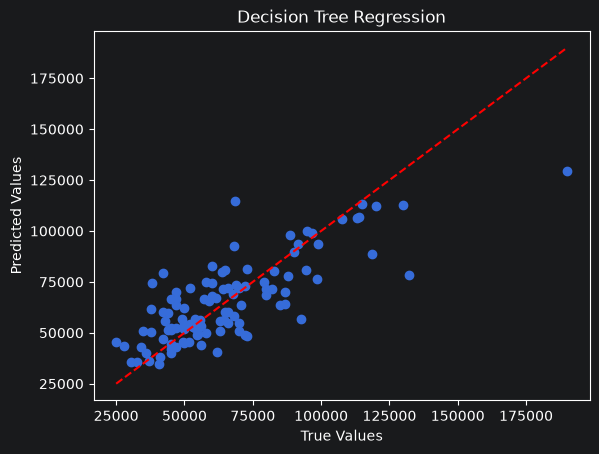

In [40]:
plt.figure()
plt.scatter(y_test, y_pred)
plt.xlabel('True Values')
plt.ylabel('Predicted Values')
plt.title('Decision Tree Regression')
high = max(y_test.max(), y_pred.max())
low = min(y_test.min(), y_pred.min())
plt.plot([low, high], [low, high], 'r--')
plt.show()